## Importing librarys

In [ ]:

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series analysis
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Machine learning
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Warnings
import warnings
warnings.filterwarnings('ignore')

## Upload and load dataset

In [ ]:

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully")

print("Shape:", df.shape)

display(df.head())


Saving london_weather_data_1979_to_2023 (1).csv to london_weather_data_1979_to_2023 (1).csv
Dataset loaded successfully
Shape: (16436, 11)


,DATE,TX,TN,TG,SS,SD,RR,QQ,PP,HU,CC
0,19790101,23,-75,-41.0,70,9.0,4,52.0,10190.0,83.0,2.0
1,19790102,16,-75,-26.0,17,8.0,0,27.0,10253.0,76.0,6.0
2,19790103,13,-72,-28.0,0,4.0,0,13.0,10205.0,86.0,5.0
3,19790104,-3,-65,-26.0,0,2.0,0,13.0,10084.0,68.0,8.0
4,19790105,56,-14,-8.0,20,1.0,0,29.0,10225.0,73.0,6.0


## Data cleaning and preprocessing

In [ ]:

# Convert DATE into datetime
df['DATE'] = pd.to_datetime(
    df['DATE'].astype(str),
    format='%Y%m%d'
)

# Set date as index
df = df.sort_values('DATE')
df = df.set_index('DATE')

# Convert scaled measurements
df['TX_C'] = df['TX'] / 10
df['TN_C'] = df['TN'] / 10
df['TG_C'] = df['TG'] / 10
df['SS_Hours'] = df['SS'] / 10
df['RR_mm'] = df['RR'] / 10
df['PP_hPa'] = df['PP'] / 10

# Time-related variables
df['Year'] = df.index.year
df['Month'] = df.index.month
df['Day'] = df.index.day
df['Season'] = df['Month'].map({
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
})

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicates
print("Duplicate dates:", df.index.duplicated().sum())

display(df.head())


Missing values:
TX             0
TN             0
TG            29
SS             0
SD          1075
RR             0
QQ            25
PP             4
HU            57
CC            18
TX_C           0
TN_C           0
TG_C          29
SS_Hours       0
RR_mm          0
PP_hPa         4
Year           0
Month          0
Day            0
Season         0
dtype: int64
Duplicate dates: 0


,TX,TN,TG,SS,SD,RR,QQ,PP,HU,CC,TX_C,TN_C,TG_C,SS_Hours,RR_mm,PP_hPa,Year,Month,Day,Season
DATE,,,,,,,,,,,,,,,,,,,,
1979-01-01,23,-75,-41.0,70,9.0,4,52.0,10190.0,83.0,2.0,2.3,-7.5,-4.1,7.0,0.4,1019.0,1979,1,1,Winter
1979-01-02,16,-75,-26.0,17,8.0,0,27.0,10253.0,76.0,6.0,1.6,-7.5,-2.6,1.7,0.0,1025.3,1979,1,2,Winter
1979-01-03,13,-72,-28.0,0,4.0,0,13.0,10205.0,86.0,5.0,1.3,-7.2,-2.8,0.0,0.0,1020.5,1979,1,3,Winter
1979-01-04,-3,-65,-26.0,0,2.0,0,13.0,10084.0,68.0,8.0,-0.3,-6.5,-2.6,0.0,0.0,1008.4,1979,1,4,Winter
1979-01-05,56,-14,-8.0,20,1.0,0,29.0,10225.0,73.0,6.0,5.6,-1.4,-0.8,2.0,0.0,1022.5,1979,1,5,Winter


## Exploratory Data Analysis
Descriptive statistics

In [ ]:

# Select important weather variables
weather_cols = [
    'TX_C', 'TN_C', 'TG_C',
    'SS_Hours', 'RR_mm',
    'QQ', 'PP_hPa', 'HU', 'CC'
]

# Descriptive statistics
display(df[weather_cols].describe().round(2))


,TX_C,TN_C,TG_C,SS_Hours,RR_mm,QQ,PP_hPa,HU,CC
count,16436.00,16436.00,16407.00,16436.00,16436.00,16411.00,16432.00,16379.00,16418.00
mean,15.47,7.60,11.54,4.32,1.68,119.52,1015.39,76.28,5.26
std,6.57,5.34,5.75,4.00,3.76,89.27,10.52,10.52,2.09
min,-6.20,-11.80,-7.60,0.00,0.00,0.00,959.60,33.00,0.00
25%,10.60,3.60,7.20,0.40,0.00,42.00,1009.10,69.00,4.00
50%,15.10,7.80,11.40,3.50,0.00,96.00,1016.20,77.00,6.00
75%,20.40,11.80,16.10,7.10,1.60,187.00,1022.50,84.00,7.00
max,40.20,22.30,30.90,15.70,61.80,402.00,1047.70,100.00,9.00


Missing values visualization

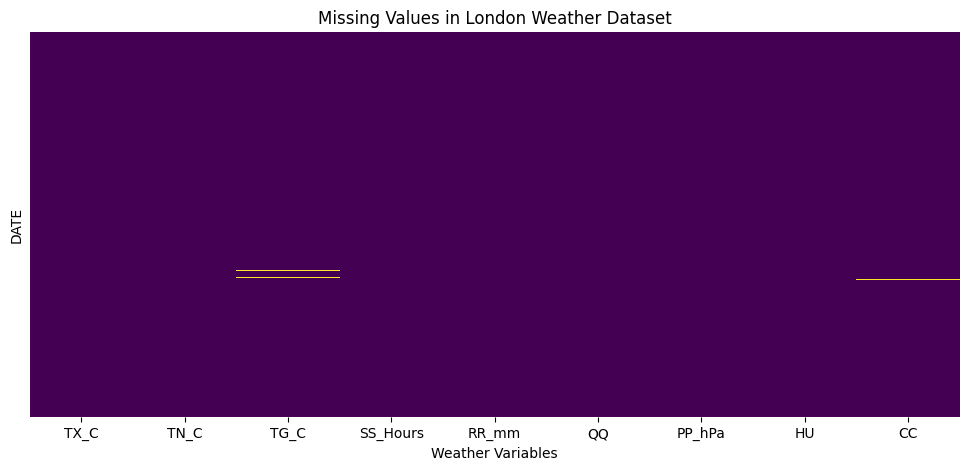

In [ ]:

plt.figure(figsize=(12, 5))

sns.heatmap(
    df[weather_cols].isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values in London Weather Dataset')
plt.xlabel('Weather Variables')
plt.show()


Temperature trends over time

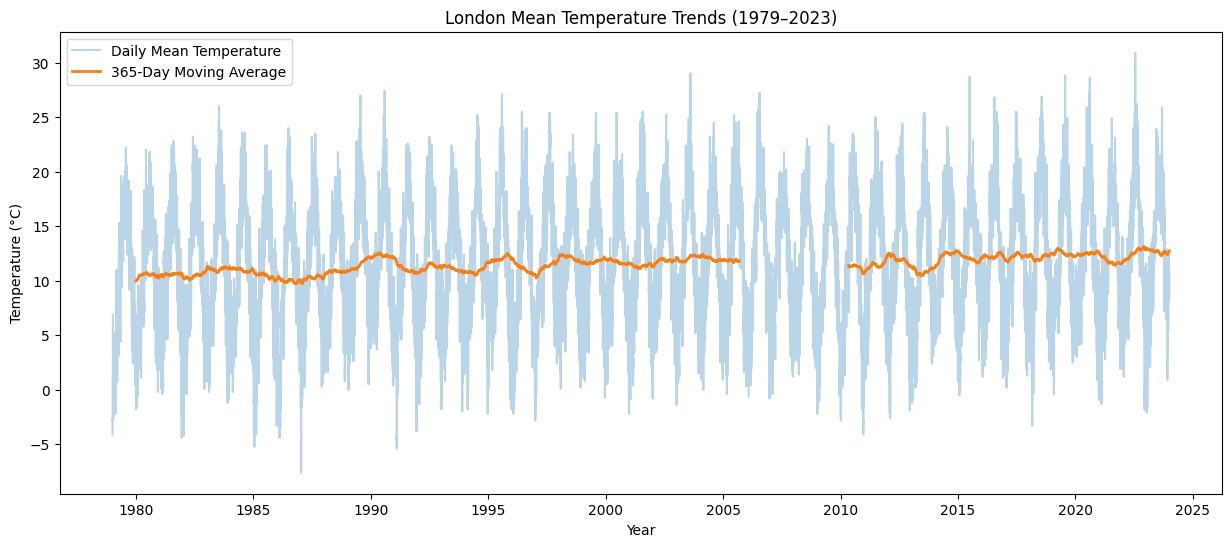

In [ ]:

plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df['TG_C'],
    alpha=0.3,
    label='Daily Mean Temperature'
)

plt.plot(
    df['TG_C'].rolling(365).mean(),
    linewidth=2,
    label='365-Day Moving Average'
)

plt.title('London Mean Temperature Trends (1979–2023)')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()


Monthly temperature patterns

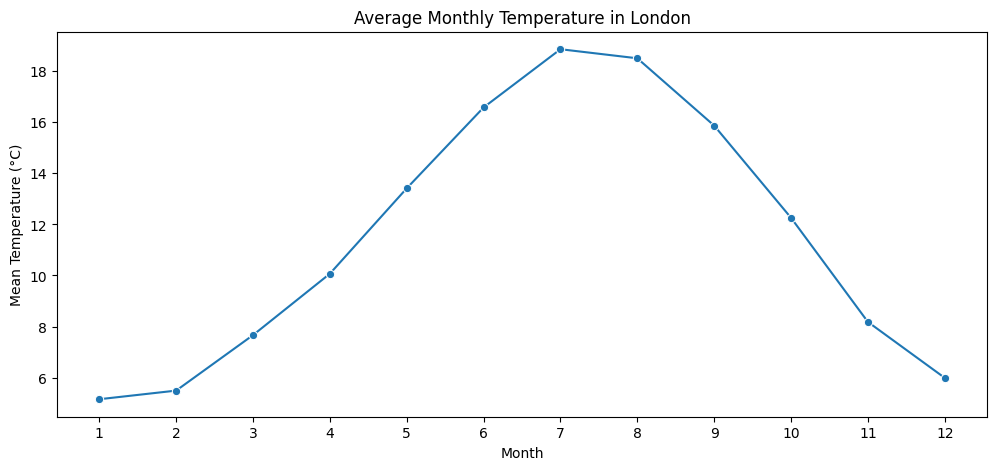

In [ ]:

monthly_temp = df.groupby('Month')['TG_C'].mean()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_temp.index,
    y=monthly_temp.values,
    marker='o'
)

plt.title('Average Monthly Temperature in London')
plt.xlabel('Month')
plt.ylabel('Mean Temperature (°C)')
plt.xticks(range(1, 13))
plt.show()


Seasonal weather analysis

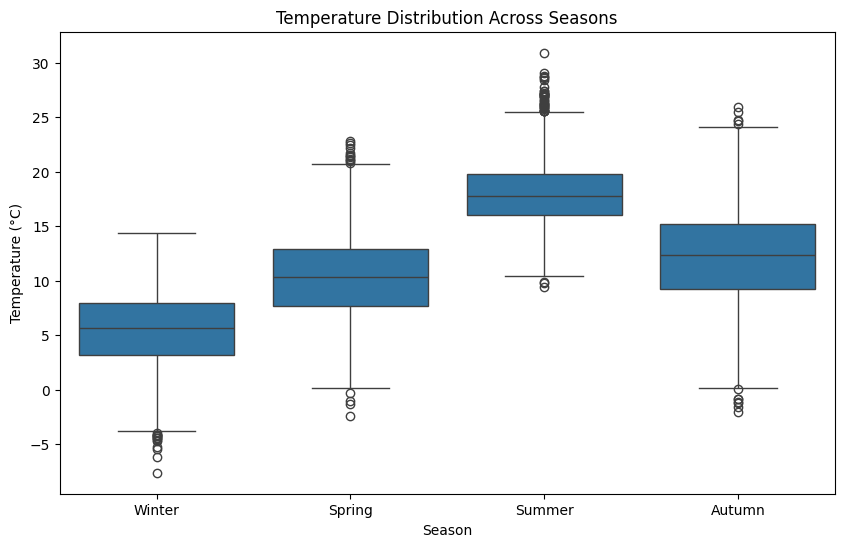

In [ ]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Season',
    y='TG_C',
    order=['Winter', 'Spring', 'Summer', 'Autumn']
)

plt.title('Temperature Distribution Across Seasons')
plt.xlabel('Season')
plt.ylabel('Temperature (°C)')
plt.show()


Correlation analysis

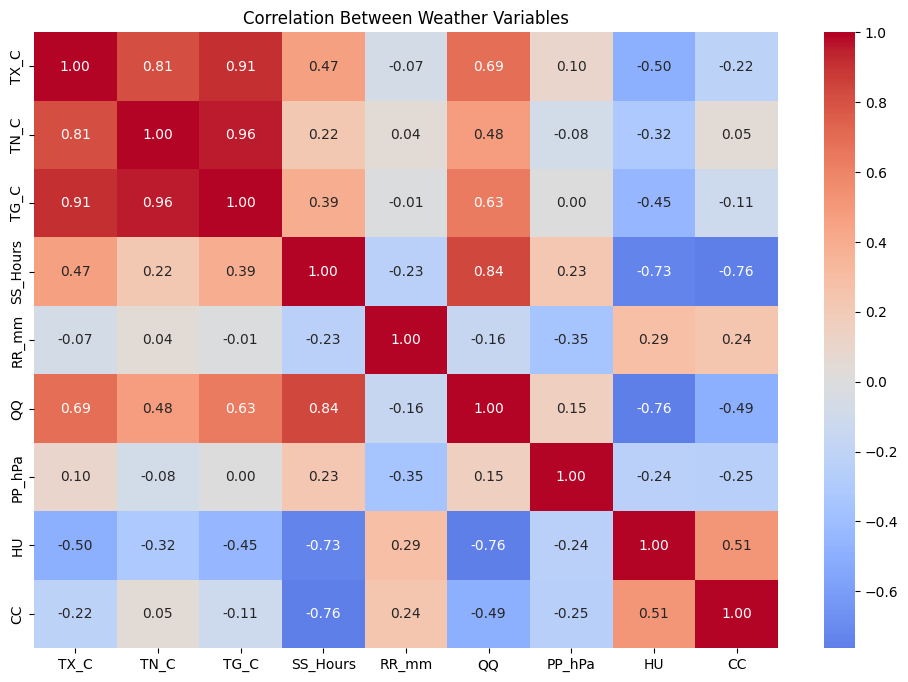

In [ ]:

plt.figure(figsize=(12, 8))

correlation = df[weather_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Between Weather Variables')
plt.show()


Annual rainfall and sunshine

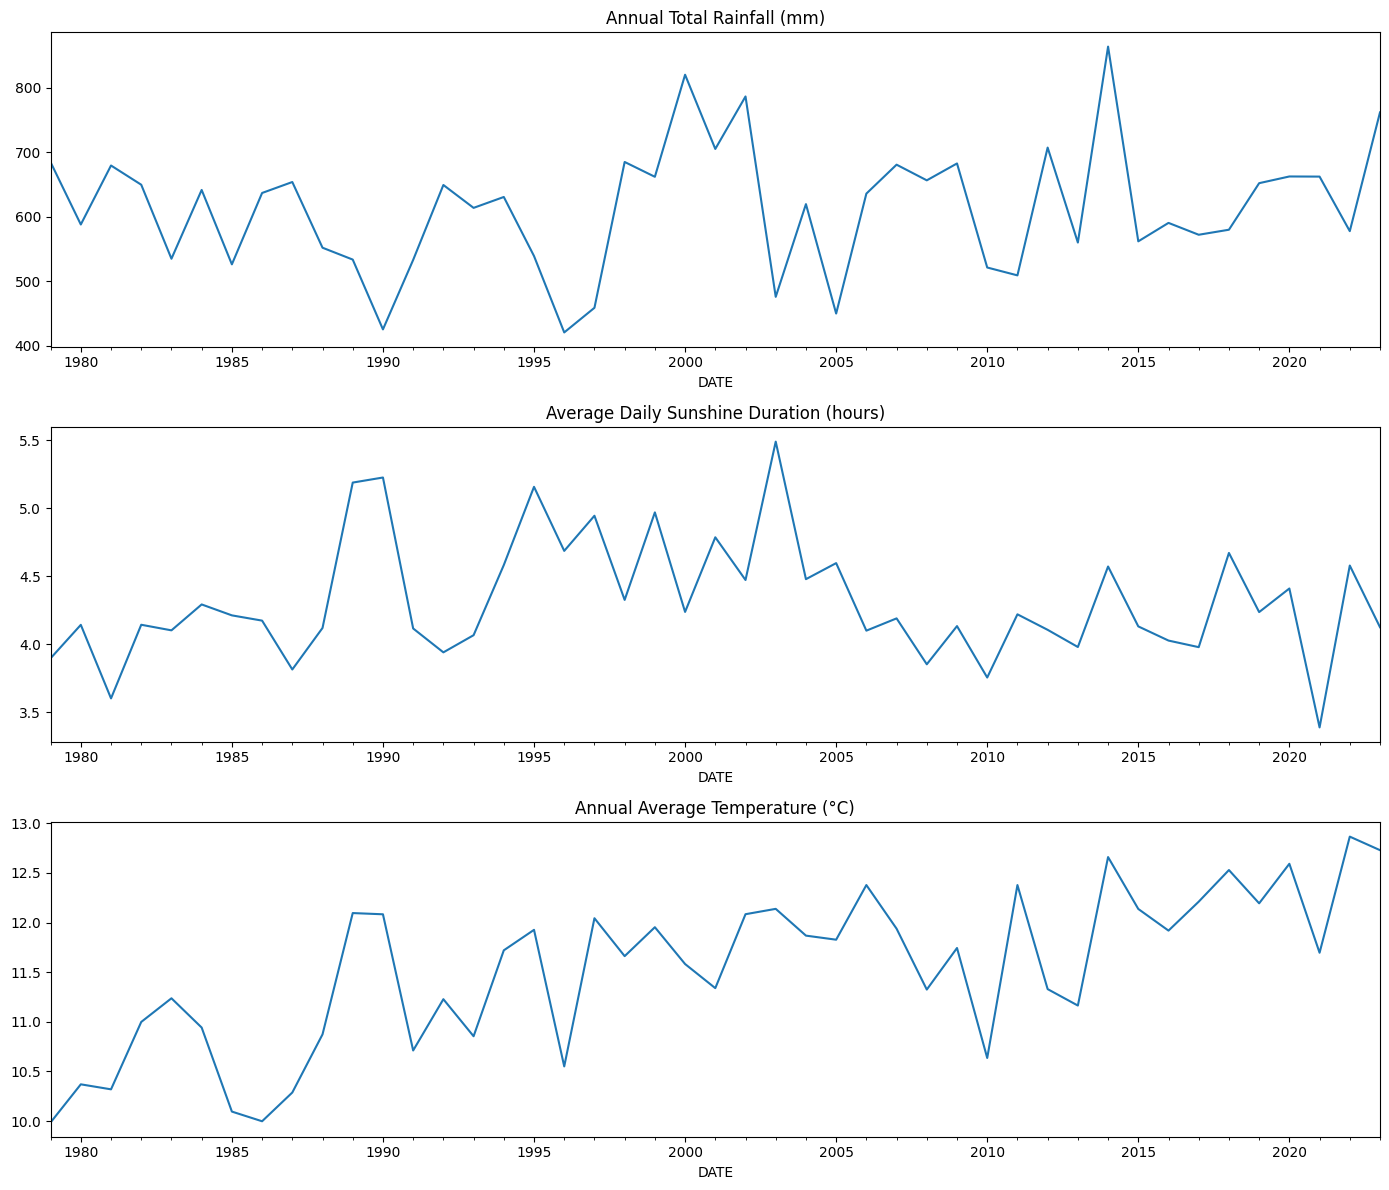

In [ ]:

annual = df.resample('YE').agg({
    'RR_mm': 'sum',
    'SS_Hours': 'mean',
    'TG_C': 'mean'
})

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

annual['RR_mm'].plot(ax=axes[0])
axes[0].set_title('Annual Total Rainfall (mm)')

annual['SS_Hours'].plot(ax=axes[1])
axes[1].set_title('Average Daily Sunshine Duration (hours)')

annual['TG_C'].plot(ax=axes[2])
axes[2].set_title('Annual Average Temperature (°C)')

plt.tight_layout()
plt.show()


## Time Series Analysis
monthly time series

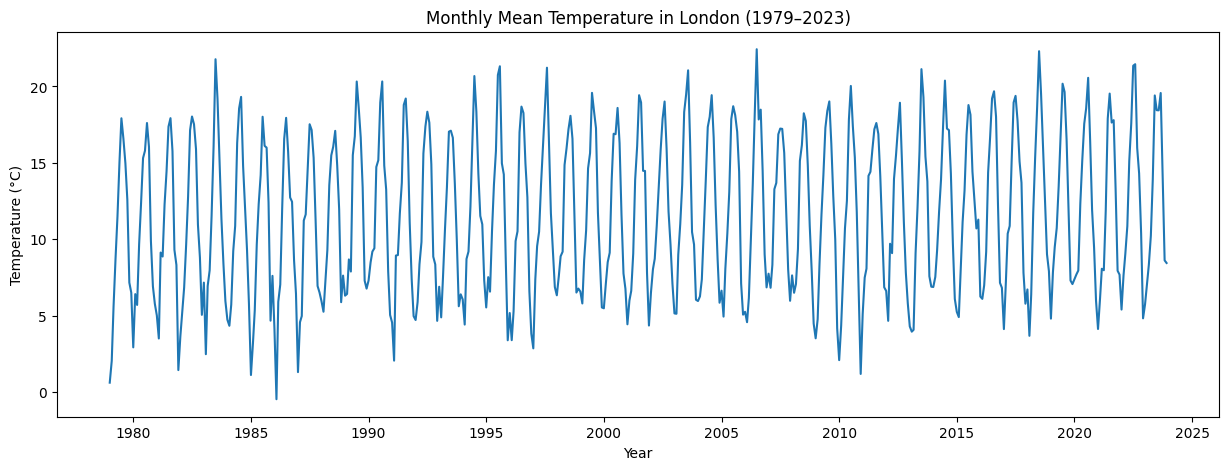

count    540.000000
mean      11.503295
std        5.111140
min       -0.467857
25%        7.095968
50%       11.056452
75%       16.066801
max       22.438710
Name: TG_C, dtype: float64


In [ ]:

# Monthly average temperature
ts = df['TG_C'].resample('MS').mean()

# Handle any missing monthly observations
ts = ts.interpolate(method='time')

plt.figure(figsize=(15, 5))
plt.plot(ts)

plt.title('Monthly Mean Temperature in London (1979–2023)')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.show()

print(ts.describe())


Seasonal decomposition

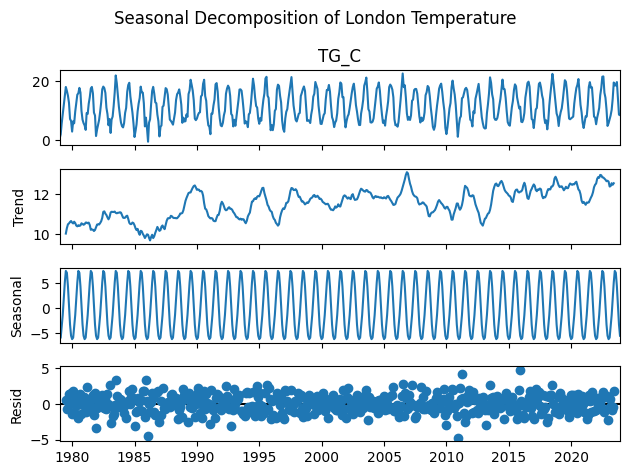

In [ ]:

decomposition = seasonal_decompose(
    ts,
    model='additive',
    period=12
)

decomposition.plot()
plt.suptitle('Seasonal Decomposition of London Temperature')
plt.tight_layout()
plt.show()


## Test for stationarity (ADF test)

In [ ]:

adf_result = adfuller(ts.dropna())

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("The series is stationary.")
else:
    print("The series is non-stationary.")


ADF Statistic: -3.332204228449675
P-value: 0.013498899217564034
The series is stationary.


ACF and PACF plots

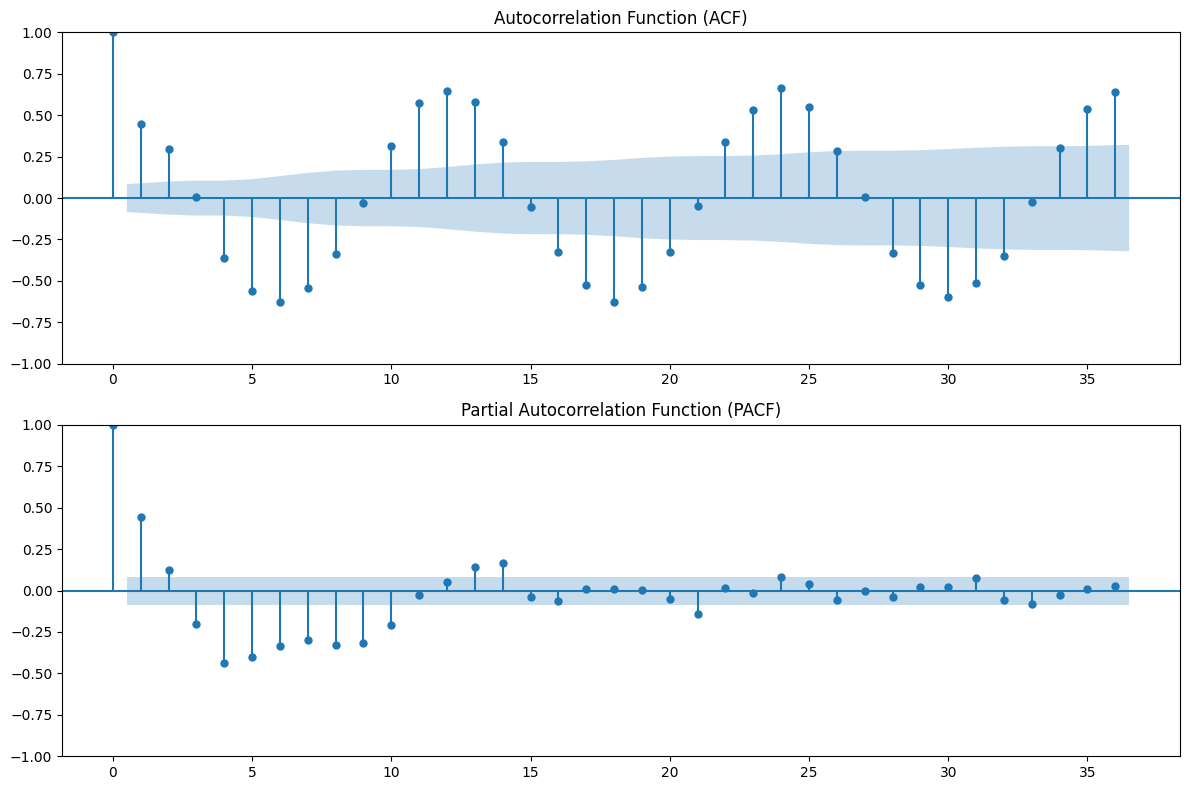

In [ ]:

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(ts.diff().dropna(), lags=36, ax=axes[0])
plot_pacf(ts.diff().dropna(), lags=36, ax=axes[1])

axes[0].set_title('Autocorrelation Function (ACF)')
axes[1].set_title('Partial Autocorrelation Function (PACF)')

plt.tight_layout()
plt.show()


## Machine Learning and Forecasting
The three approaches.
- Seasonal Naive for	Baseline forecasting model
- SARIMA forTraditional statistical time-series model
- Random Forest Regressor for	Machine learning model

Prepare training and testing data
We will use:
- Training data: January 1979 – December 2014.
- Testing data: January 2015 – December 2023.

In [ ]:

train = ts.loc[:'2014-12-01']
test = ts.loc['2015-01-01':]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training period:", train.index.min(), train.index.max())
print("Testing period:", test.index.min(), test.index.max())


Training observations: 432
Testing observations: 108
Training period: 1979-01-01 00:00:00 2014-12-01 00:00:00
Testing period: 2015-01-01 00:00:00 2023-12-01 00:00:00


SARIMA model

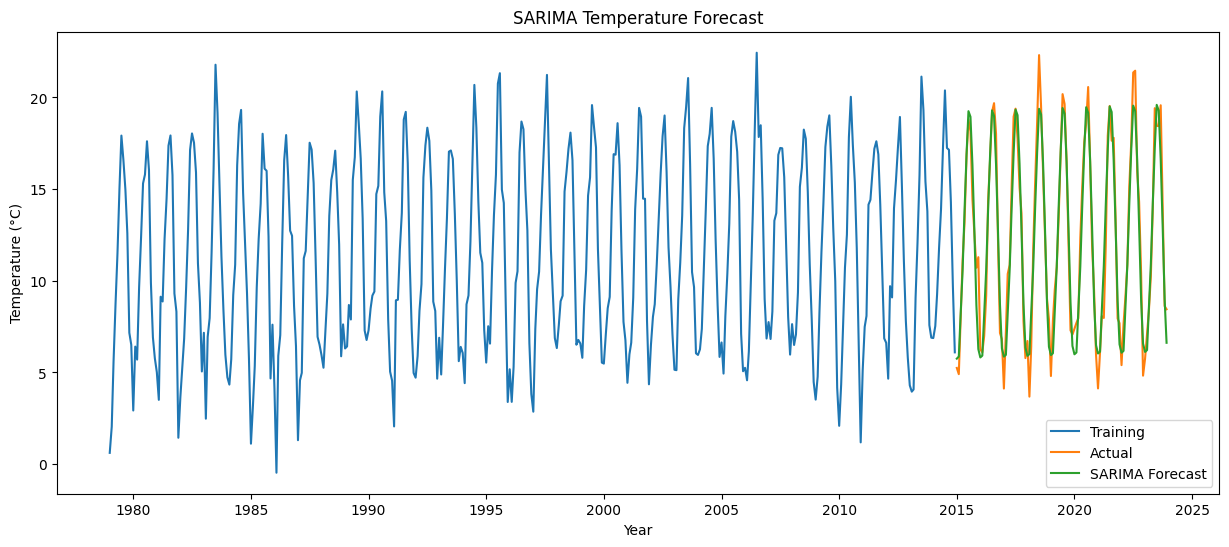

In [ ]:

sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

sarima_predictions = sarima_fit.forecast(
    steps=len(test)
)

plt.figure(figsize=(15, 6))

plt.plot(train.index, train, label='Training')
plt.plot(test.index, test, label='Actual')
plt.plot(
    test.index,
    sarima_predictions,
    label='SARIMA Forecast'
)

plt.title('SARIMA Temperature Forecast')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()


Random Forest machine learning

Random Forest requires us to create features from historical temperature observations.

We will use:
- Previous month's temperature.
- Temperature from two and three months earlier.
- Temperature from six and twelve months earlier.
- Three-month and twelve-month rolling averages.
- Month of the year.

In [ ]:

ml_data = pd.DataFrame(index=ts.index)

ml_data['target'] = ts

# Lag variables
for lag in [1, 2, 3, 6, 12]:
    ml_data[f'lag_{lag}'] = ts.shift(lag)

# Rolling averages using past observations only
ml_data['rolling_3'] = ts.shift(1).rolling(3).mean()
ml_data['rolling_12'] = ts.shift(1).rolling(12).mean()

# Seasonal calendar variables
ml_data['month'] = ml_data.index.month

ml_data['month_sin'] = np.sin(
    2 * np.pi * ml_data['month'] / 12
)

ml_data['month_cos'] = np.cos(
    2 * np.pi * ml_data['month'] / 12
)

ml_data = ml_data.dropna()

features = [
    'lag_1', 'lag_2', 'lag_3',
    'lag_6', 'lag_12',
    'rolling_3', 'rolling_12',
    'month_sin', 'month_cos'
]

ml_train = ml_data.loc[:'2014-12-01']
ml_test = ml_data.loc['2015-01-01':]

X_train = ml_train[features]
y_train = ml_train['target']

X_test = ml_test[features]
y_test = ml_test['target']

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest training completed.")


Random Forest training completed.


Model accuracy

We will compare the models using:
- MAE: Mean Absolute Error.
- RMSE: Root Mean Squared Error.
- R²: Coefficient of Determination.

In [ ]:

def evaluate_model(actual, predicted, model_name):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    return {
        'Model': model_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    }


# Seasonal naive forecast
naive_predictions = pd.Series(
    index=test.index,
    data=[
        ts.loc[date - pd.DateOffset(years=1)]
        for date in test.index
    ]
)

results = []

results.append(
    evaluate_model(test, naive_predictions, 'Seasonal Naive')
)

results.append(
    evaluate_model(test, sarima_predictions, 'SARIMA')
)

results.append(
    evaluate_model(y_test, rf_predictions, 'Random Forest')
)

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,MAE,RMSE,R2
0,Seasonal Naive,1.6929,2.0491,0.8384
1,SARIMA,1.0216,1.2930,0.9356
2,Random Forest,1.2937,1.6432,0.8961


Compare model performance

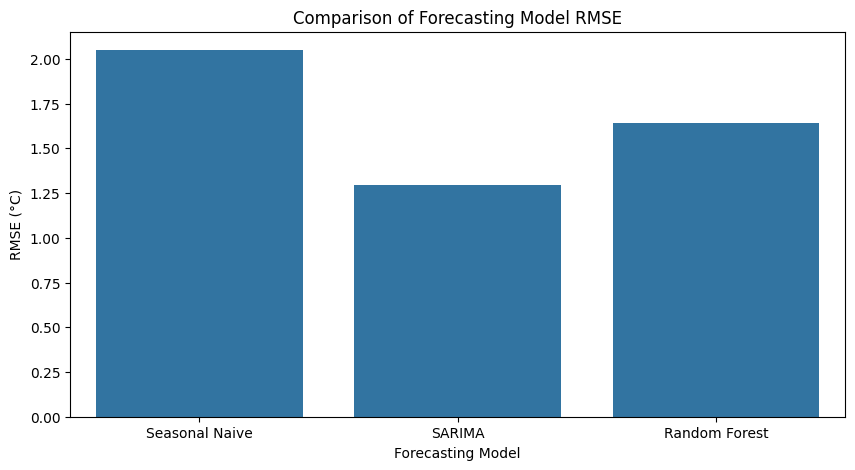

In [ ]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title('Comparison of Forecasting Model RMSE')
plt.ylabel('RMSE (°C)')
plt.xlabel('Forecasting Model')
plt.show()


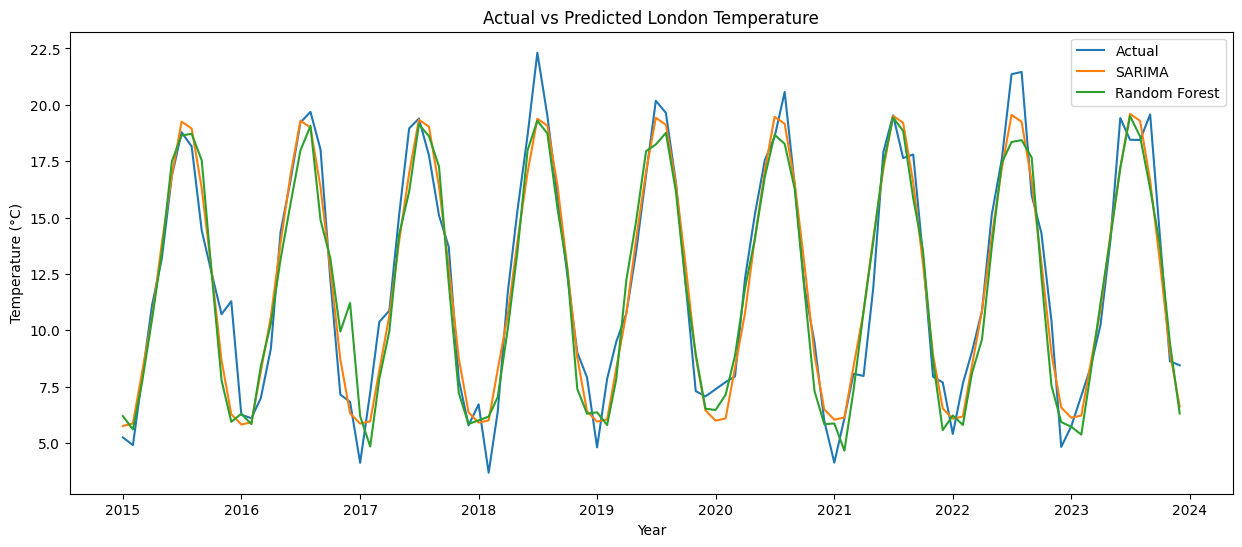

In [ ]:

plt.figure(figsize=(15, 6))

plt.plot(test.index, test, label='Actual')
plt.plot(
    test.index,
    sarima_predictions,
    label='SARIMA'
)

plt.plot(
    y_test.index,
    rf_predictions,
    label='Random Forest'
)

plt.title('Actual vs Predicted London Temperature')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()


## Forecast the next 12 months
We will use SARIMA the best-performing model after evaluating the results.

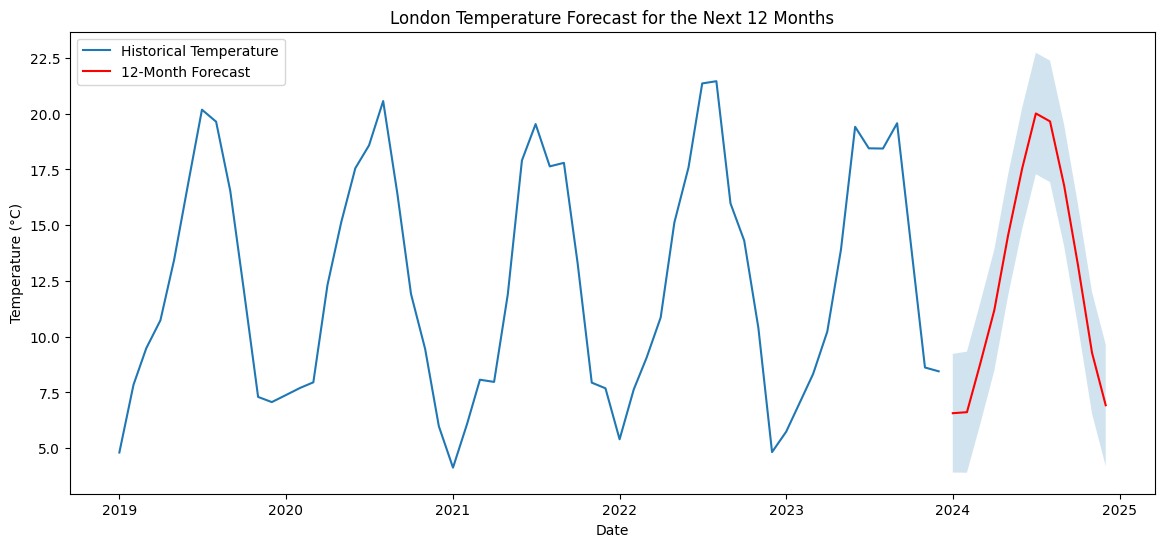

,predicted_mean
2024-01-01,6.570057
2024-02-01,6.615301
2024-03-01,8.782621
2024-04-01,11.196628
2024-05-01,14.534155
2024-06-01,17.545957
2024-07-01,20.011635
2024-08-01,19.656405
2024-09-01,16.769893
2024-10-01,13.238887


In [31]:
# Forecast the next 12 months using SARIMA (trained on all historical data)
future_forecast = final_fit.get_forecast(steps=12)

forecast_mean = future_forecast.predicted_mean
forecast_ci = future_forecast.conf_int()

plt.figure(figsize=(14, 6))

plt.plot(ts.index[-60:], ts.iloc[-60:],
         label='Historical Temperature')

plt.plot(
    forecast_mean.index,
    forecast_mean,
    label='12-Month Forecast',
    color='red'
)

plt.fill_between(
    forecast_ci.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    alpha=0.2
)

plt.title('London Temperature Forecast for the Next 12 Months')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()

display(forecast_mean)